In [1]:
import scanpy as sc
adata_fibroblast = sc.read("../h5ad/adata_fibroblast.h5ad")
sc.pp.normalize_total(adata_fibroblast, target_sum=1e6)
sc.pp.log1p(adata_fibroblast)

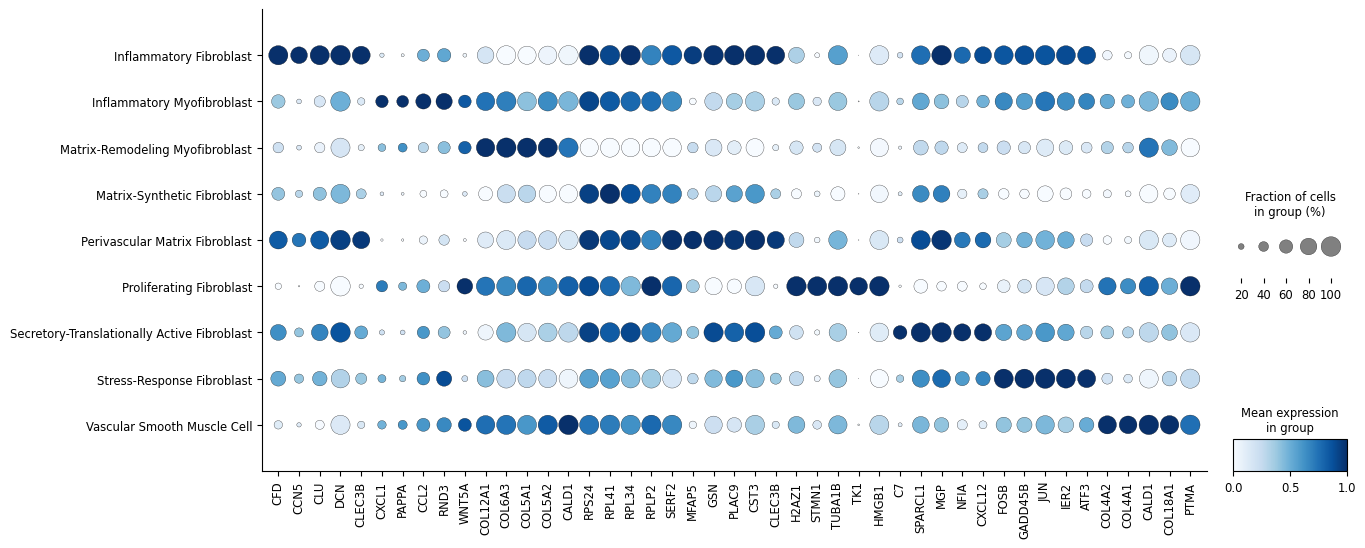

In [2]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. Differential expression analysis
# ==========================================
sc.tl.rank_genes_groups(adata_fibroblast, groupby='celltype', method='wilcoxon')

# ==========================================
# 2. Extract marker genes
# ==========================================
n_genes = 5
markers_to_plot = []

# Get all cell type names (order matches the rank_genes_groups result)
groups = adata_fibroblast.uns['rank_genes_groups']['names'].dtype.names

# Loop through each subcluster and take the top n_genes genes
for group in groups:
    genes = adata_fibroblast.uns['rank_genes_groups']['names'][group][:n_genes]
    markers_to_plot.extend(genes)

# ==========================================
# 3. Plot DotPlot
# ==========================================
dp = sc.pl.dotplot(
    adata_fibroblast,
    markers_to_plot,
    groupby='celltype',
    dendrogram=False,
    standard_scale='var',
    figsize=(14, 6),
    cmap="Blues",
    return_fig=True,
    show=False,
)

# Remove top and right spines from all main plot axes
axes_dict = dp.get_axes()
main_ax = axes_dict.get("mainplot_ax")

if main_ax is not None:
    main_ax.spines["top"].set_visible(False)
    main_ax.spines["right"].set_visible(False)
else:
    for ax_name, ax in axes_dict.items():
        if ax_name == "colorbar_ax":
            continue
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

plt.show()